# Technical indicators

Each indicator is one function in its own cell. Every function takes a DataFrame `df`
(columns `open, high, low, close, volume`, one row per candle, oldest first), calculates the
indicator for **every row**, adds the result as new column(s) to `df`, and returns `df`.
The first rows of an indicator are `NaN` until enough history exists.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. SMA — Simple Moving Average
`SMA_t = (close_t + close_{t-1} + ... + close_{t-n+1}) / n`

In [2]:
def add_sma(df, period=20, column='close'):
    df[f'sma_{period}'] = df[column].rolling(window=period, min_periods=period).mean()
    return df

## 2. EMA — Exponential Moving Average
`k = 2 / (n + 1)`, `EMA_t = close_t * k + EMA_{t-1} * (1 - k)`, seeded with the SMA of the first `n` closes.

In [3]:
def add_ema(df, period=20, column='close'):
    values = df[column].to_numpy(dtype=float)
    ema = np.full(len(values), np.nan)
    if len(values) >= period:
        k = 2 / (period + 1)
        ema[period - 1] = values[:period].mean()
        for i in range(period, len(values)):
            ema[i] = values[i] * k + ema[i - 1] * (1 - k)
    df[f'ema_{period}'] = ema
    return df

## 3. DMA — Displaced Moving Average
An SMA shifted forward by `displacement` candles: `DMA_t = SMA_{t-d}`.

In [32]:
def add_dma(df, period=20, displacement=5, column='close'):
    sma = df[column].rolling(window=period, min_periods=period).mean()
    df[f'dma_{period}_{displacement}'] = sma.shift(displacement)
    return df

## 4. Bollinger Bands
`middle = SMA_n`, `upper = middle + k * std_n`, `lower = middle - k * std_n` (population standard deviation).

In [26]:
def add_bollinger_bands(df, period=20, num_std=2, column='close'):
    rolling = df[column].rolling(window=period, min_periods=period)
    middle = rolling.mean()
    std = rolling.std(ddof=0)
    df['bb_middle'] = middle
    df['bb_upper'] = middle + num_std * std
    df['bb_lower'] = middle - num_std * std
    df['bb_middle'] = middle
    return df

## 5. RSI — Relative Strength Index (Wilder)
`RS = avg_gain / avg_loss`, `RSI = 100 - 100 / (1 + RS)`.
First averages are simple means of the first `n` changes; afterwards `avg = (prev_avg * (n-1) + current) / n`.

In [6]:
def add_rsi(df, period=14, column='close'):
    change = df[column].diff().to_numpy(dtype=float)
    gain = np.where(change > 0, change, 0.0)
    loss = np.where(change < 0, -change, 0.0)
    rsi = np.full(len(df), np.nan)
    if len(df) > period:
        avg_gain = gain[1:period + 1].mean()
        avg_loss = loss[1:period + 1].mean()
        for i in range(period, len(df)):
            if i > period:
                avg_gain = (avg_gain * (period - 1) + gain[i]) / period
                avg_loss = (avg_loss * (period - 1) + loss[i]) / period
            if avg_loss == 0:
                rsi[i] = 100.0 if avg_gain > 0 else 50.0
            else:
                rsi[i] = 100 - 100 / (1 + avg_gain / avg_loss)
    df[f'rsi_{period}'] = rsi
    return df

## 6. Momentum
`Momentum_t = close_t - close_{t-n}`

In [7]:
def add_momentum(df, period=10, column='close'):
    df[f'momentum_{period}'] = df[column] - df[column].shift(period)
    return df

## 7. MACD — Moving Average Convergence Divergence
`MACD = EMA_fast - EMA_slow`, `signal = EMA_signal(MACD)`, `histogram = MACD - signal`.

In [8]:
def add_macd(df, fast=12, slow=26, signal=9, column='close'):
    fast_ema = df[column].ewm(span=fast, adjust=False, min_periods=fast).mean()
    slow_ema = df[column].ewm(span=slow, adjust=False, min_periods=slow).mean()
    macd = fast_ema - slow_ema
    macd_signal = macd.ewm(span=signal, adjust=False, min_periods=signal).mean()
    df['macd'] = macd
    df['macd_signal'] = macd_signal
    df['macd_histogram'] = macd - macd_signal
    return df

## 8. Volume
The raw `volume` column is the traded quantity per candle. This function validates it as numeric
and adds a volume moving average (`volume_ma_n`) plus relative volume (`volume / volume_ma_n`).

In [9]:
def add_volume(df, period=20):
    df['volume'] = pd.to_numeric(df['volume'], errors='raise')
    df[f'volume_ma_{period}'] = df['volume'].rolling(window=period, min_periods=period).mean()
    df[f'relative_volume_{period}'] = df['volume'] / df[f'volume_ma_{period}']
    return df

## 9. Volume delta
`volume_delta = buy_volume - sell_volume` (signed, not absolute).
If `buy_volume` / `sell_volume` are missing, it is estimated as `volume * (close - open) / (high - low)`,
which is negative for red candles and positive for green candles.

In [10]:
def add_volume_delta(df):
    if {'buy_volume', 'sell_volume'}.issubset(df.columns):
        df['volume_delta'] = df['buy_volume'] - df['sell_volume']
    else:
        candle_range = (df['high'] - df['low']).replace(0, np.nan)
        body_ratio = ((df['close'] - df['open']) / candle_range).fillna(0.0)
        df['volume_delta'] = df['volume'] * body_ratio
    return df

## 10. Ichimoku Cloud
- Tenkan-sen = (highest high + lowest low) / 2 over `tenkan` candles
- Kijun-sen = (highest high + lowest low) / 2 over `kijun` candles
- Senkou Span A = (Tenkan + Kijun) / 2, plotted `displacement` candles ahead
- Senkou Span B = (highest high + lowest low) / 2 over `senkou_b` candles, plotted `displacement` candles ahead
- Chikou Span = close plotted `displacement` candles back (uses future prices, so do not use it as an ML feature)

In [11]:
def add_ichimoku(df, tenkan=9, kijun=26, senkou_b=52, displacement=26):
    def midpoint(period):
        high = df['high'].rolling(window=period, min_periods=period).max()
        low = df['low'].rolling(window=period, min_periods=period).min()
        return (high + low) / 2

    tenkan_sen = midpoint(tenkan)
    kijun_sen = midpoint(kijun)
    df['ichimoku_tenkan'] = tenkan_sen
    df['ichimoku_kijun'] = kijun_sen
    df['ichimoku_senkou_a'] = ((tenkan_sen + kijun_sen) / 2).shift(displacement)
    df['ichimoku_senkou_b'] = midpoint(senkou_b).shift(displacement)
    df['ichimoku_chikou'] = df['close'].shift(-displacement)
    return df

## Example: apply every indicator

In [62]:
data_path = 'datapoints/XAU/XAU_5m.csv'  # run from the repository root
df = pd.read_csv(data_path, parse_dates=['time'], index_col='time')

#df = add_sma(df)
#df = add_ema(df)
#df = add_dma(df, period=20, displacement=0)
#df = add_bollinger_bands(df)
#df = add_ichimoku(df)

#df = add_rsi(df, period=14)
#df = add_momentum(df, period=10)
#df = add_macd(df, fast=12, slow=26, signal=9)
#df = add_volume(df, period=20)
df = add_volume_delta(df)


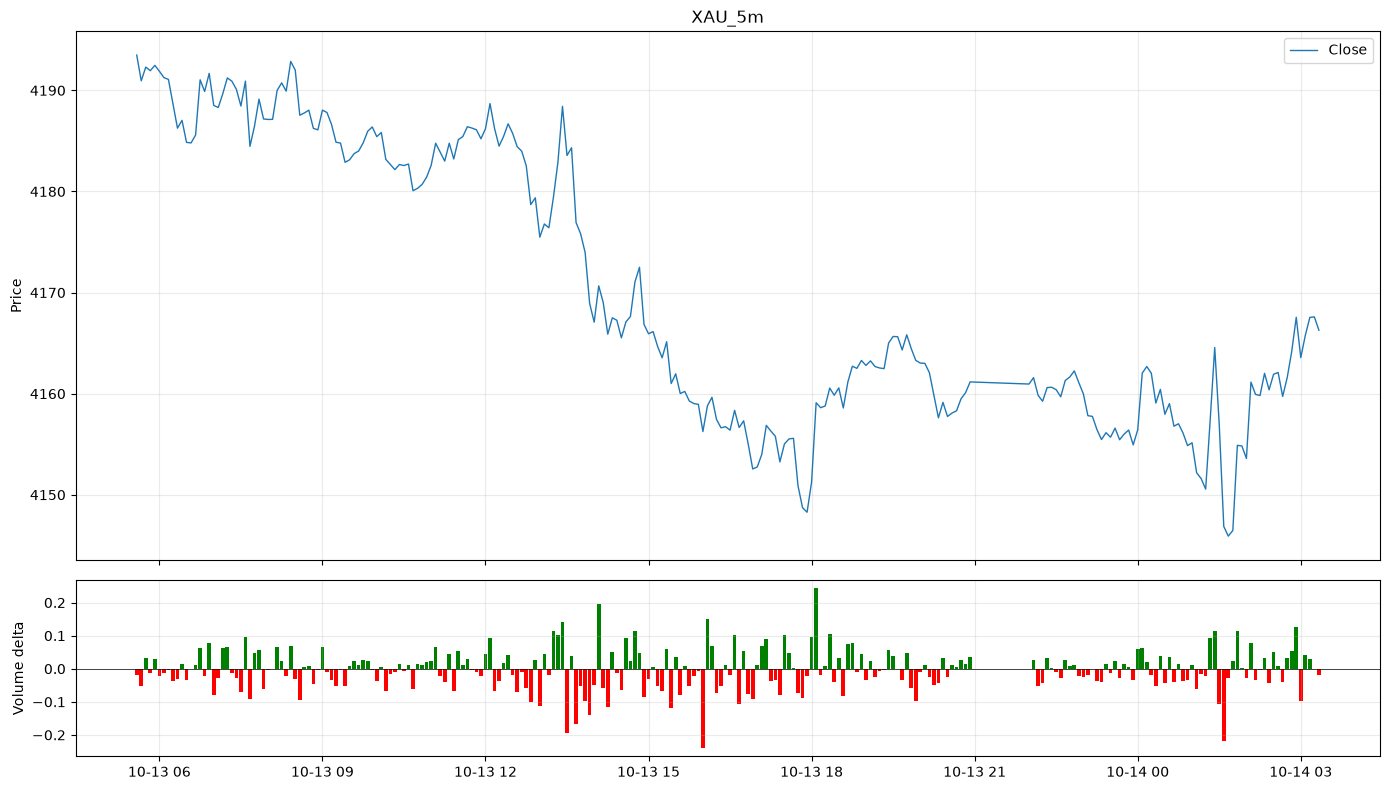

In [63]:
plot_data = df.tail(250) # Display the last 250 data points - depending on the candle period = 250 * 5 = 1250 minutes = ~21 hours
fig, (ax, ax_ind) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax.set_title(data_path.split('/')[-1].split('.')[0])
ax.plot(plot_data.index, plot_data['close'], label='Close', linewidth=1)

### On-the-Chart Indicators ###
#ax.plot(plot_data.index, plot_data['sma_20'], label='SMA 20', linewidth=1) # Simple Moving Average with a period of 20

#ax.plot(plot_data.index, plot_data['ema_20'], label='EMA 20', linewidth=1) # Exponential Moving Average with a period of 20

#ax.plot(plot_data.index, plot_data['dma_20_0'], label='DMA 20', linewidth=1) # Double Moving Average with a period of 20 and displacement of 0

#ax.plot(plot_data.index, plot_data['bb_upper'], label='Bollinger upper', linewidth=0.8) # Bollinger Bands upper line
#ax.plot(plot_data.index, plot_data['bb_lower'], label='Bollinger lower', linewidth=0.8) # Bollinger Bands lower line
#ax.plot(plot_data.index, plot_data['bb_middle'], label='Bollinger middle', linewidth=0.8) # Bollinger Bands middle line

#ax.fill_between(plot_data.index, plot_data['ichimoku_senkou_a'], plot_data['ichimoku_senkou_b'], alpha=0.2, label='Ichimoku cloud') # Ichimoku Cloud

ax.set_ylabel('Price')
ax.legend()
ax.grid(True, alpha=0.25)

### separate-chart Indicators ###

"""val = plot_data['rsi_14']
ax_ind.plot(plot_data.index, val, label='RSI', color='purple', linewidth=1)
ax_ind.plot(plot_data.index, [70]*len(plot_data.index), label='Overbought', color='red', linewidth=1)
ax_ind.plot(plot_data.index, [30]*len(plot_data.index), label='Oversold', color='green', linewidth=1)
#ax_ind.set_ylim(0, 100)
ax_ind.set_ylabel('RSI')
ax_ind.grid(False)"""

"""val = plot_data['momentum_10']
ax_ind.plot(plot_data.index, val, label='Momentum', color='purple', linewidth=1)
#ax_ind.set_ylim(0, 100)
ax_ind.set_ylabel('Momentum')
ax_ind.grid(False)"""

"""
ax_ind.plot(plot_data.index, plot_data['macd'], label='MACD', color='purple', linewidth=1)
ax_ind.plot(plot_data.index, plot_data['macd_signal'], label='Signal', color='red', linewidth=1)
bar_width = (plot_data.index[1] - plot_data.index[0]) * 0.8
ax_ind.bar(plot_data.index, plot_data['macd_histogram'], width=bar_width, color=np.where(plot_data['macd_histogram'] >= 0, 'green', 'red'))
#ax_ind.set_ylim(0, 100)
ax_ind.set_ylabel('MACD')
ax_ind.grid(False)"""


"""ax_ind.plot(plot_data.index, plot_data['volume'], label='Volume', color='purple', linewidth=1)
#ax_ind.plot(plot_data.index, plot_data['volume_ma_20'], label='volume_ma_20', color='red', linewidth=1)
#ax_ind.plot(plot_data.index, plot_data['relative_volume_20'], label='relative_volume_20', color='blue', linewidth=1)
#ax_ind.set_ylim(0, 100)
ax_ind.grid(False)"""

delta = plot_data['volume_delta']
bar_width = (plot_data.index[1] - plot_data.index[0]) * 0.8
ax_ind.bar(plot_data.index, delta, width=bar_width, color=np.where(delta >= 0, 'green', 'red'))
ax_ind.axhline(0, color='black', linewidth=0.5)
ax_ind.set_ylabel('Volume delta')
ax_ind.grid(True, alpha=0.25)


fig.tight_layout()
plt.show()